In [117]:
import pandas as pd
import numpy as np
import mne
import matplotlib.pyplot as plt

In [118]:
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)

In [119]:
def read_prep_eeg(eeg_file_path_vhdr, low_freq=None, high_freq=None):

    '''
    Read and preprocess raw data to get EEG channels x time samples dataframe

    '''
    
    raw = mne.io.read_raw_brainvision(eeg_file_path_vhdr, preload=True)
    channels = raw.ch_names[:63]
    
    raw.set_channel_types({
    "Mano DX": "misc",
    "Mano SX": "misc",
    "ECG": "ecg",
    "pressione": "misc"})
    
    if low_freq is not None or high_freq is not None:
        
        raw = raw.copy().filter(l_freq=low_freq, h_freq=high_freq)
        
    raw = raw.pick("eeg")
    #data_mean_subtracted = data - np.mean(data, axis=1, keepdims=True)
    #df = pd.DataFrame(data_mean_subtracted.T, columns=channels)
    
    return raw

In [120]:
# Read Smits11.vhdr file from the directory. File path is needed if file is not in the directory
file = "Smits11.vhdr"
raw = read_prep_eeg(file, low_freq = 1.0)

Extracting parameters from Smits11.vhdr...
Setting channel info structure...
Reading 0 ... 954718  =      0.000 ...   190.944 secs...
Filtering raw data in 1 contiguous segment
Setting up high-pass filter at 1 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal highpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Filter length: 16501 samples (3.300 s)



In [121]:
raw

<RawBrainVision | Smits11.eeg, 63 x 954719 (190.9 s), ~458.9 MiB, data loaded>

In [122]:
sfreq = 5000
pre = int(0.020 * sfreq)   
post = int(0.100 * sfreq)
time_epoch = np.arange(-pre, post) /sfreq

def get_erp(raw, low_freq=None, high_freq=None):

    # Get events from annotations
    events, event_id = mne.events_from_annotations(raw)
    samples = events[:, 0]

    # Remove near-duplicate triggers
    clean = [samples[0]]
    for s in samples[1:]:
        if s - clean[-1] > 100:
            clean.append(s)

    triglist_clean = np.array(clean, dtype=np.int64)

    epochs = []
    for trigger in triglist_clean:
        if trigger - pre < 0 or trigger + post > raw.n_times:
            continue

        epoch, times = raw[:, trigger - pre: trigger + post]
        epochs.append(epoch)

    epochs = np.stack(epochs, axis=0)   # (n_epochs, n_channels, n_times)
    erp = np.mean(epochs, axis=0)       # (n_channels, n_times)

    # baseline window 11-14 ms after stimulus
    b_start = pre + int(0.011 * sfreq)
    b_end = pre + int(0.014 * sfreq)

    baseline = np.mean(erp[:, b_start:b_end], axis=1, keepdims=True)
    erp_corrected = erp - baseline

    return erp_corrected

In [123]:
erp_mean = get_erp(raw, low_freq=1.0)

Used Annotations descriptions: [np.str_('Response/R  7'), np.str_('Response/R 15')]


In [124]:
d.shape

(63, 600)

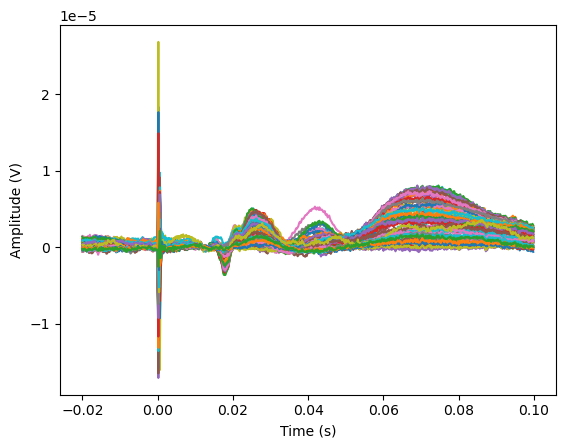

In [125]:
for i in range(63):
    plt.plot(time_epoch, erp_mean[i])

plt.xlabel("Time (s)")
plt.ylabel("Amplitude (V)")
plt.show()

In [126]:
def plot_topographies(raw, tmin = None, tmax = None):

    '''
    select time limits min and max in ms for which the topographies are desired
    in case tmin and tmax are not selected, 0.015 - 0.025 will be shown automatically
    '''

    if tmin is not None or tmax is not None:
        tmin_peak = tmin
        tmax_peak = tmax
    else:
    
        tmin_peak = 0.015
        tmax_peak = 0.025

    time_mask = (time_epoch >= tmin_peak) & (time_epoch <= tmax_peak)
    time_idx = np.where(time_mask)[0]
    times_to_plot = time_epoch[time_idx]


    info = raw.info.copy()

    info = mne.pick_info(info, mne.pick_types(info, eeg=True))

    if info.get("dig", None) is None:
        montage = mne.channels.make_standard_montage("standard_1020")
        info.set_montage(montage, on_missing="ignore")

    n_maps = len(time_idx)

    n_cols = 5
    n_rows = int(np.ceil(n_maps / n_cols))

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(3 * n_cols, 3 * n_rows))
    axes = np.array(axes).reshape(-1)

    #vmax = np.max(np.abs(erp_mean[:, time_idx]))
    #vlim = (-vmax, vmax)

    for ax, idx in zip(axes, time_idx):
        topo_vals = erp_mean[:, idx]   # channel values at this time point

        im, _ = mne.viz.plot_topomap(
            topo_vals/topo_vals.sum(),
            info,
            axes=ax,
            show=False,
            cmap="jet",
        )
        cbar = fig.colorbar(im, ax=ax, orientation='vertical', fraction=0.05, pad=0.1)
        cbar.set_label("normed amplitude")
        ax.set_title(f"{time_epoch[idx]*1000:.1f} ms")

    for ax in axes[n_maps:]:
        ax.axis("off")

    #cbar = fig.colorbar(im, ax=axes[:n_maps], shrink=0.7, orientation="horizontal")
    #cbar_ax = fig.add_axes([0.2, 0.05, 0.6, 0.02])

    #cbar = fig.colorbar(im, cax=cbar_ax, orientation='horizontal')
    #cbar.set_label("normed amplitude")

    plt.tight_layout()
    plt.show()

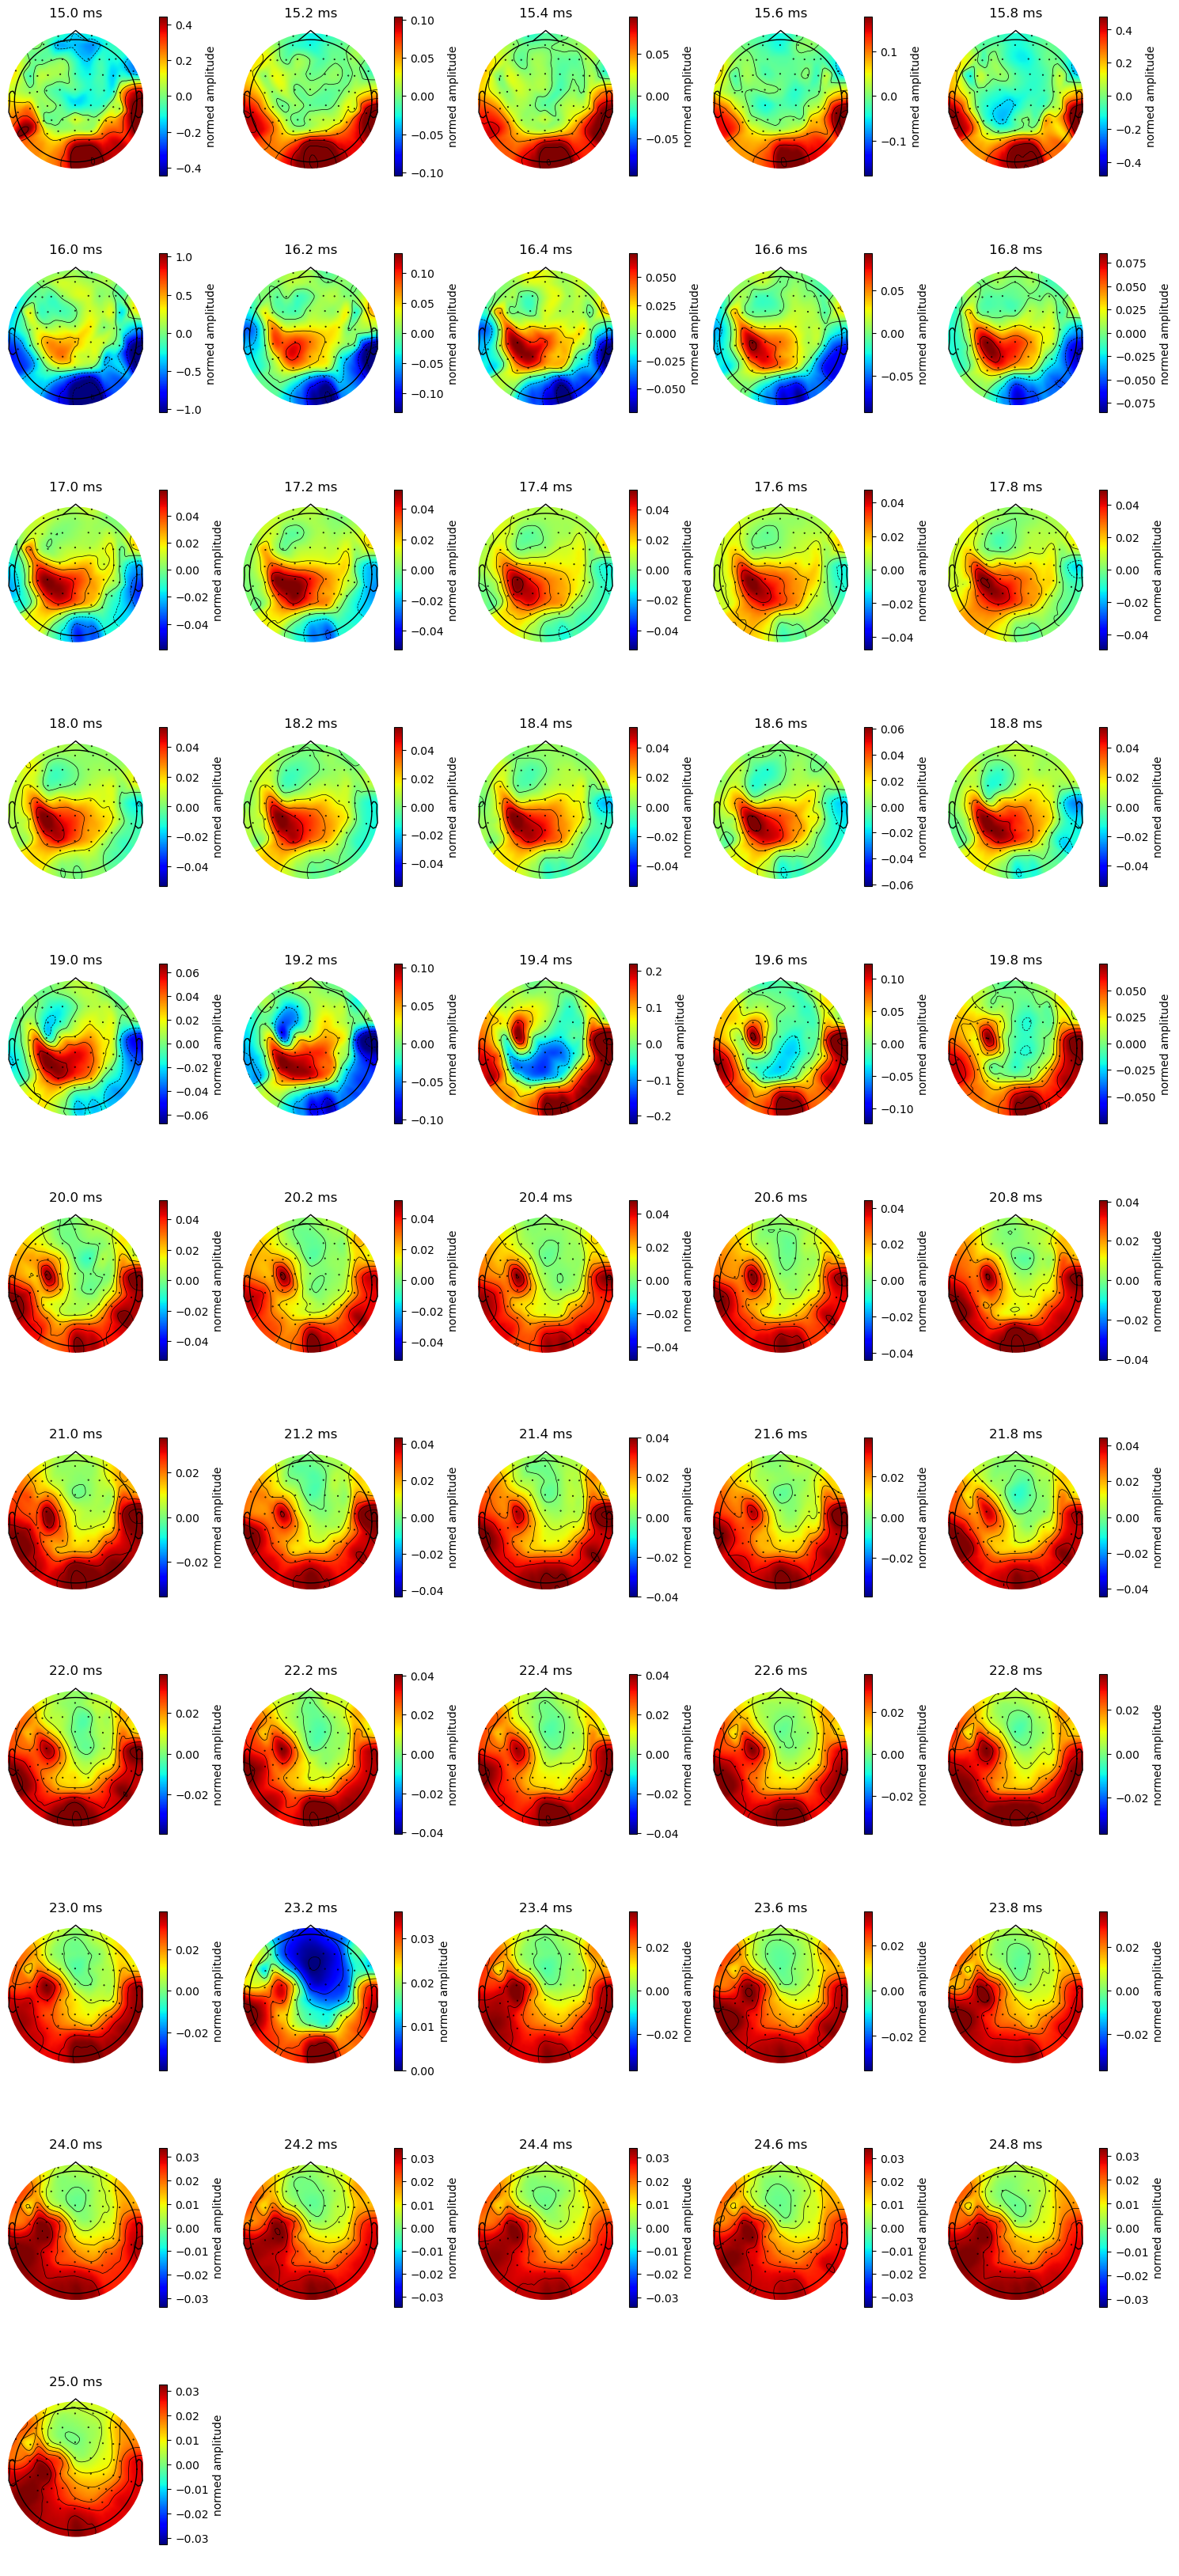

In [127]:
# Topographies for Smits11
plot_topographies(raw)

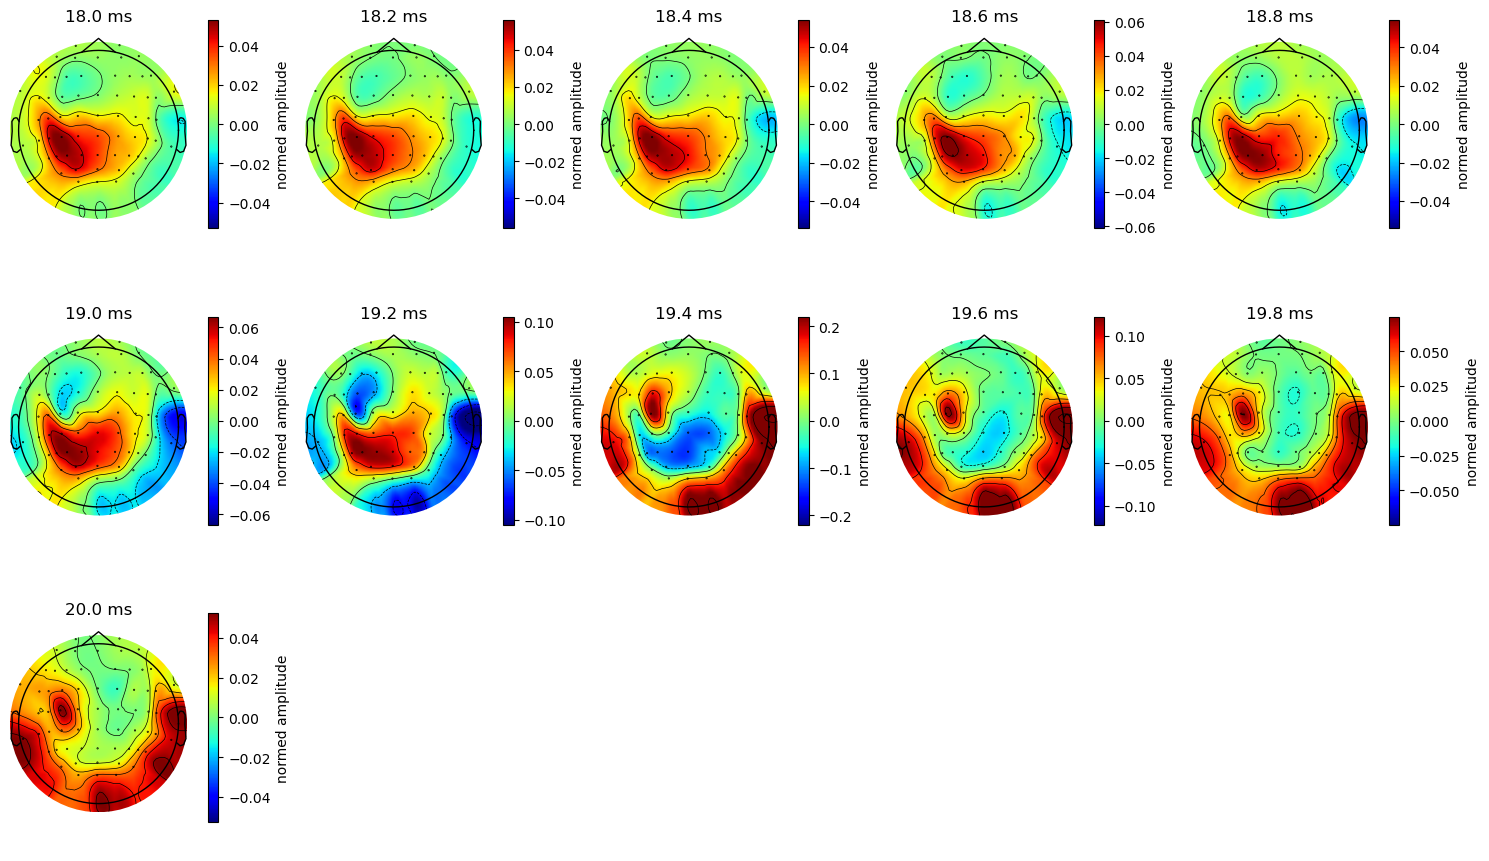

In [128]:
# Topographies for Smits11 with selected time window
plot_topographies(raw, tmin = 0.018, tmax=0.020)

In [137]:
def select_topography(raw, time_point=0.018, normalize=False):
    
    '''
    Plot one EEG topography at a selected time point.

    Parameters
    ----------
    raw : mne.io.Raw
        Raw object used only for channel info / montage.
    erp_mean : ndarray, shape (n_channels, n_times)
        ERP data.
    time_epoch : ndarray, shape (n_times,)
        Time vector in seconds.
    time_point : float
        Desired time point in seconds. Example: 0.020 = 20 ms.
    normalize : bool
        If True, divide topo values by their sum.
    '''
    
    idx = np.argmin(np.abs(time_epoch - time_point))
    actual_time = time_epoch[idx]

    info = raw.info.copy()
    picks = mne.pick_types(info, eeg=True)
    info = mne.pick_info(info, picks)

    # set montage if missing
    if info.get("dig", None) is None:
        montage = mne.channels.make_standard_montage("standard_1020")
        info.set_montage(montage, on_missing="ignore")

    topo_vals = erp_mean[:, idx]

    if normalize:
        denom = topo_vals.sum()
        if denom != 0:
            topo_vals = topo_vals / denom


    fig, ax = plt.subplots(figsize=(6, 5))
    im, _ = mne.viz.plot_topomap(
        topo_vals,
        info,
        axes=ax,
        show=False,
        cmap="jet"
    )

    cbar = fig.colorbar(im, ax=ax, orientation="vertical", fraction=0.05, pad=0.08)
    cbar.set_label("Amplitude" if not normalize else "Normalized amplitude")

    ax.set_title(f"{actual_time * 1000:.1f} ms")
    plt.tight_layout()
    plt.show()

    return fig, ax

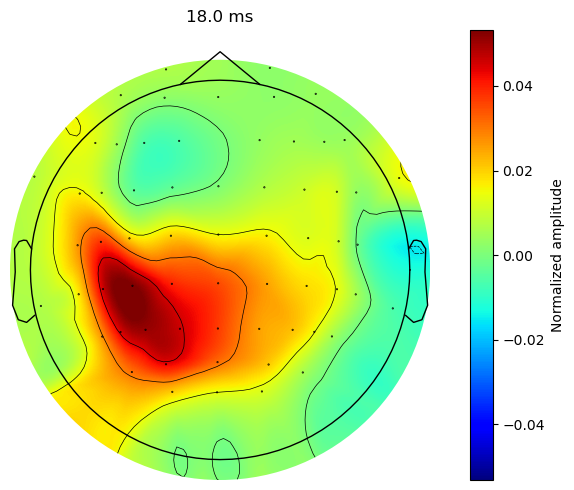

(<Figure size 600x500 with 2 Axes>, <Axes: title={'center': '18.0 ms'}>)

In [138]:
select_topography(raw, time_point = 0.018, normalize=True)